# Preprocessing: `match_results`  (Resultados de partidos)

Análisis y limpieza individual de esta tabla. Rango: **2018-2025** (temporadas completas).
Salida limpia → `data/processed/match_results_clean.csv`.

Estructura estándar: carga → vista general → columnas → cobertura temporal →
duplicados → distribuciones → limpieza específica → export.

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

RAW  = Path("../data/raw/fbref_r")      # ajusta si tu estructura difiere
PROC = Path("../data/processed")
PROC.mkdir(parents=True, exist_ok=True)

PREFIJO = "laliga"
TABLA   = "match_results"
SEASON_MIN, SEASON_MAX = 2018, 2025
CLAVE = ["Season_End_Year", "Date", "Home", "Away"]

df = pd.read_csv(RAW / f"{PREFIJO}_{TABLA}.csv")
if "Season_End_Year" in df.columns:
    df = df[df["Season_End_Year"].between(SEASON_MIN, SEASON_MAX)].reset_index(drop=True)
print("shape:", df.shape)

shape: (3040, 20)


## 1. Vista general

In [14]:
display(df.head(5))
display(df.tail(5))

,Competition_Name,Gender,Country,Season_End_Year,Round,Wk,Day,Date,Time,Home,HomeGoals,Home_xG,Away,AwayGoals,Away_xG,Attendance,Venue,Referee,Notes,MatchURL
0,La Liga,M,ESP,2018,NaN,1,Fri,2017-08-18,20:15,Leganés,1.0,1.3,Alavés,0.0,1.1,9231.0,Estadio Municipal de Butarque,José Munuera,NaN,https://fbref.com/en/matches/5c28c716/Leganes-...
1,La Liga,M,ESP,2018,NaN,1,Fri,2017-08-18,22:15,Valencia,1.0,1.4,Las Palmas,0.0,0.2,35971.0,Estadio de Mestalla,Jesús Gil,NaN,https://fbref.com/en/matches/05e8105f/Valencia...
2,La Liga,M,ESP,2018,NaN,1,Sat,2017-08-19,18:15,Celta Vigo,2.0,1.8,Real Sociedad,3.0,2.1,16961.0,Estadio de Balaídos,Antonio Matéu Lahoz,NaN,https://fbref.com/en/matches/02357c77/Celta-Vi...
3,La Liga,M,ESP,2018,NaN,1,Sat,2017-08-19,20:15,Girona,2.0,2.2,Atlético Madrid,2.0,0.7,11511.0,Estadi Municipal de Montilivi,Juan Martínez,NaN,https://fbref.com/en/matches/a8696eaa/Girona-A...
4,La Liga,M,ESP,2018,NaN,1,Sat,2017-08-19,22:15,Sevilla,1.0,2.4,Espanyol,1.0,1.3,30487.0,Estadio Ramón Sánchez Pizjuán,Alejandro Hernández,NaN,https://fbref.com/en/matches/c8acb4f7/Sevilla-...


,Competition_Name,Gender,Country,Season_End_Year,Round,Wk,Day,Date,Time,Home,HomeGoals,Home_xG,Away,AwayGoals,Away_xG,Attendance,Venue,Referee,Notes,MatchURL
3035,La Liga,M,ESP,2025,NaN,38,Sat,2025-05-24,21:00,Alavés,1.0,2.0,Osasuna,1.0,1.6,19274.0,Estadio de Mendizorroza,Guillermo Cuadra,NaN,https://fbref.com/en/matches/ed820dc1/Alaves-O...
3036,La Liga,M,ESP,2025,NaN,38,Sat,2025-05-24,21:00,Getafe,1.0,0.4,Celta Vigo,2.0,1.5,12862.0,Coliseum Alfonso Pérez,Juan Martínez,NaN,https://fbref.com/en/matches/4303125c/Getafe-C...
3037,La Liga,M,ESP,2025,NaN,38,Sun,2025-05-25,14:00,Girona,0.0,0.0,Atlético Madrid,4.0,2.7,11546.0,Estadi Municipal de Montilivi,Jesús Gil,NaN,https://fbref.com/en/matches/cb8011f0/Girona-A...
3038,La Liga,M,ESP,2025,NaN,38,Sun,2025-05-25,16:15,Villarreal,4.0,1.1,Sevilla,2.0,1.5,17758.0,Estadio de la Cerámica,Javier Alberola,NaN,https://fbref.com/en/matches/b724ff67/Villarre...
3039,La Liga,M,ESP,2025,NaN,38,Sun,2025-05-25,21:00,Athletic Club,0.0,1.2,Barcelona,3.0,3.5,50231.0,San Mamés,Pablo González,NaN,https://fbref.com/en/matches/20bdd334/Athletic...


## 2. Columnas: tipos, nulos, únicos

In [15]:
resumen = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_nulos": df.isna().sum(),
    "pct_nulos": (df.isna().mean() * 100).round(1),
    "n_unicos": df.nunique(),
}).sort_values("pct_nulos", ascending=False)
display(resumen)

# valores unicos de columnas de baja cardinalidad
for c in df.columns:
    nu = df[c].nunique(dropna=True)
    if nu <= 15:
        print(f"{c} ({nu}):", sorted(df[c].dropna().unique().tolist()))

,dtype,n_nulos,pct_nulos,n_unicos
Notes,float64,3040,100.0,0
Round,float64,3040,100.0,0
Attendance,float64,488,16.1,2463
Competition_Name,str,0,0.0,1
Season_End_Year,int64,0,0.0,8
Country,str,0,0.0,1
Gender,str,0,0.0,1
Wk,int64,0,0.0,38
Time,str,0,0.0,26
Home,str,0,0.0,29


Competition_Name (1): ['La Liga']
Gender (1): ['M']
Country (1): ['ESP']
Season_End_Year (8): [2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]
Round (0): []
Day (7): ['Fri', 'Mon', 'Sat', 'Sun', 'Thu', 'Tue', 'Wed']
HomeGoals (9): [0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0]
AwayGoals (8): [0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0]
Notes (0): []


## 3. Cobertura temporal
Filas por temporada — detecta años incompletos (los datos se congelaron el 18/09/2025;
algunas tablas se actualizaron por última vez en oct-2024).

Season_End_Year
2018    380
2019    380
2020    380
2021    380
2022    380
2023    380
2024    380
2025    380
Name: count, dtype: int64


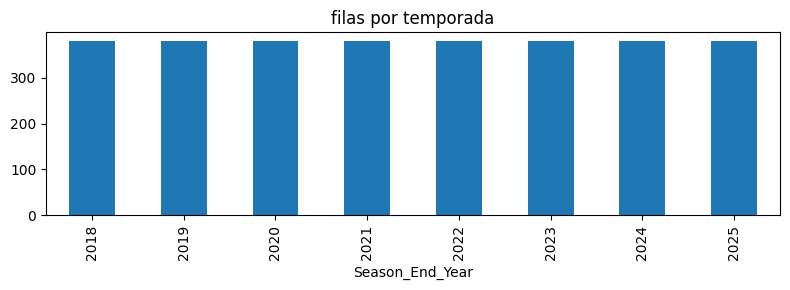

In [16]:
if "Season_End_Year" in df.columns:
    por_temp = df["Season_End_Year"].value_counts().sort_index()
    print(por_temp)
    por_temp.plot(kind="bar", figsize=(8,3), title="filas por temporada")
    plt.tight_layout(); plt.show()

## 4. Duplicados por clave natural

In [17]:
clave = [c for c in CLAVE if c in df.columns]
dup = df.duplicated(subset=clave).sum()
print(f"duplicados exactos por {clave}: {dup}")
if dup:
    display(df[df.duplicated(subset=clave, keep=False)].sort_values(clave).head(10))

duplicados exactos por ['Season_End_Year', 'Date', 'Home', 'Away']: 0


## 5. Distribuciones numéricas

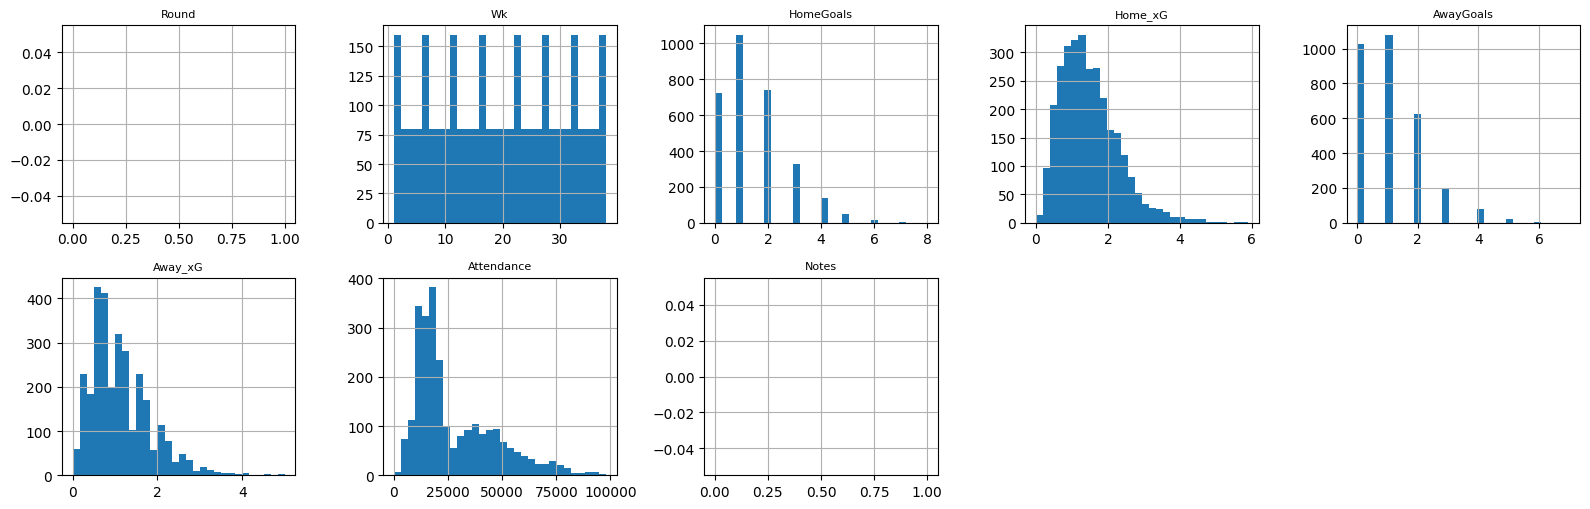

In [18]:
num = df.select_dtypes(include=[np.number]).drop(columns=["Season_End_Year","Born"], errors="ignore")
if len(num.columns):
    n = len(num.columns)
    ncols = 5
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(16, 2.6*nrows))
    for ax, c in zip(np.ravel(axes), num.columns):
        num[c].dropna().hist(bins=30, ax=ax)
        ax.set_title(c, fontsize=8)
    for ax in np.ravel(axes)[n:]:
        ax.axis("off")
    plt.tight_layout(); plt.show()

## 6. Limpieza específica
Pasos estándar + espacio para decisiones propias de esta tabla (documéntalas aquí).

In [19]:
clean = df.copy()

# columnas numericas disfrazadas de texto -> a numerico
for c in clean.columns:
    if clean[c].dtype == object and c not in ("Squad","Comp","Player","Nation","Pos","Age","Url",
                                              "Home","Away","Date","Day","Time","Round","Venue",
                                              "Referee","Notes","MatchURL","Team_or_Opponent",
                                              "Competition_Name","Gender","Country"):
        conv = pd.to_numeric(clean[c], errors="coerce")
        no_nulos = clean[c].notna().sum()
        if no_nulos and conv.notna().sum() / no_nulos > 0.7:
            clean[c] = conv

# Fecha a datetime y filtrar filas sin resultado (partidos no jugados)
clean["Date"] = pd.to_datetime(clean["Date"], errors="coerce")
antes = len(clean)
clean = clean[clean["HomeGoals"].notna() & clean["AwayGoals"].notna()]
print(f"filas sin resultado eliminadas: {antes - len(clean)}")




clean = clean.drop(columns=["Notes", "Round"], errors="ignore")
for c in ["Competition_Name", "Country", "Gender"]:
    if c in clean.columns and clean[c].nunique() <= 1:
        clean = clean.drop(columns=c)

# 2. goles a entero (ya no hay NaN tras filtrar partidos jugados)
clean["HomeGoals"] = clean["HomeGoals"].astype(int)
clean["AwayGoals"] = clean["AwayGoals"].astype(int)

# 3. descomponer la fecha en día / mes / año
clean["Anyo"] = clean["Date"].dt.year
clean["Mes"]  = clean["Date"].dt.month
clean["Dia"]  = clean["Date"].dt.day
clean["Dia_semana"] = clean["Date"].dt.dayofweek   # 0=lunes ... 6=domingo

# >>> decisiones especificas de esta tabla: anhadelas aqui <<<

print("shape tras limpieza:", clean.shape)
clean.head(3)



filas sin resultado eliminadas: 0
shape tras limpieza: (3040, 19)


,Season_End_Year,Wk,Day,Date,Time,Home,HomeGoals,Home_xG,Away,AwayGoals,Away_xG,Attendance,Venue,Referee,MatchURL,Anyo,Mes,Dia,Dia_semana
0,2018,1,Fri,2017-08-18,20:15,Leganés,1,1.3,Alavés,0,1.1,9231.0,Estadio Municipal de Butarque,José Munuera,https://fbref.com/en/matches/5c28c716/Leganes-...,2017,8,18,4
1,2018,1,Fri,2017-08-18,22:15,Valencia,1,1.4,Las Palmas,0,0.2,35971.0,Estadio de Mestalla,Jesús Gil,https://fbref.com/en/matches/05e8105f/Valencia...,2017,8,18,4
2,2018,1,Sat,2017-08-19,18:15,Celta Vigo,2,1.8,Real Sociedad,3,2.1,16961.0,Estadio de Balaídos,Antonio Matéu Lahoz,https://fbref.com/en/matches/02357c77/Celta-Vi...,2017,8,19,5


In [20]:
#Attendance 0 por covid
df.groupby("Season_End_Year")["Attendance"].apply(lambda s: s.isna().mean() * 100).round(1)

Season_End_Year
2018     0.3
2019     0.0
2020    29.2
2021    98.9
2022     0.0
2023     0.0
2024     0.0
2025     0.0
Name: Attendance, dtype: float64

In [21]:
partidos = pd.concat([
    df.groupby(["Season_End_Year", "Home"]).size(),
    df.groupby(["Season_End_Year", "Away"]).size()
], axis=1).sum(axis=1)
raros = partidos[partidos != 38]
print("equipos con != 38 partidos:", len(raros))
if len(raros): print(raros)

equipos con != 38 partidos: 0


## 7. Export a data/processed

In [22]:
out = PROC / f"{PREFIJO}_{TABLA}_clean.csv"
clean.to_csv(out, index=False)
print("guardado:", out, f"({len(clean)} filas)")

guardado: ..\data\processed\laliga_match_results_clean.csv (3040 filas)
